In [16]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
import seaborn as sns
import matplotlib.pyplot as plt

In [17]:
#passive_data = pd.read_csv('/Users/eochoa/Downloads/MPConc_WeatherMonthLocation_Passive.csv')
passive_data = pd.read_csv('evaluation_data/MPConc_WeatherMonthLocation_Passive_UPDATED.csv')
passive_data.head()

,School,Month,Conc MP (%),Conc TWP (%),Avg temperature (F),Avg dew point (F),Avg humidity (%),Avg wind speed (mph),Avg total precipitation (in)
0,FHS,Mar,0.000000,0.001139,38.817241,31.006897,75.620690,1.451724,0.074483
1,FHS,Apr,0.000000,0.007234,51.634483,40.344828,68.241379,6.162069,0.094828
2,FHS,May,0.000000,0.004479,62.853571,53.921429,75.321429,3.253571,0.098571
3,FHS,Jun,0.013514,0.009824,68.306667,60.066667,77.233333,3.150000,0.141333
4,FHS,Jul,0.000000,0.001323,70.017857,63.867857,82.321429,2.035714,0.220000


In [18]:
passive_data.columns

Index(['School', 'Month', 'Conc MP (%)', 'Conc TWP (%)', 'Avg temperature (F)',
       'Avg dew point (F)', 'Avg humidity (%)', 'Avg wind speed (mph)',
       'Avg total precipitation (in)'],
      dtype='object')

In [19]:
X_cat = pd.get_dummies(
    passive_data.loc[:, ['School', 'Month']],
    drop_first=True
)

X = passive_data.loc[:, ['Avg temperature (F)',
       'Avg dew point (F)', 'Avg humidity (%)', 'Avg wind speed (mph)',
       'Avg total precipitation (in)']]
X = sm.add_constant(X)  # adds intercept

X = pd.concat([X_cat, X], axis=1)
y = passive_data["Conc MP (%)"]*1000

model = sm.OLS(y, X).fit()

In [20]:
num_vars = ['Avg temperature (F)',
       'Avg dew point (F)', 'Avg humidity (%)', 'Avg wind speed (mph)',
       'Avg total precipitation (in)']
cat_vars = ['School', 'Month']

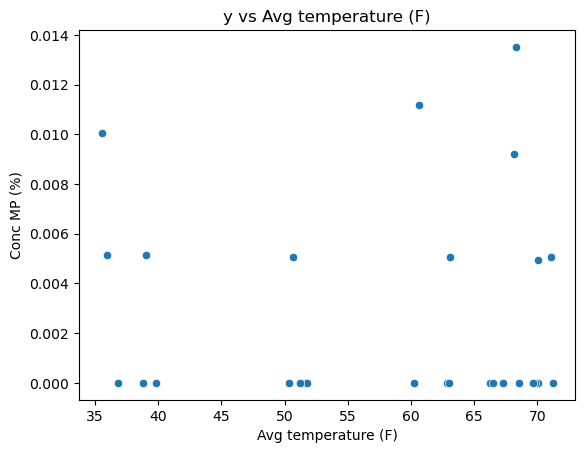

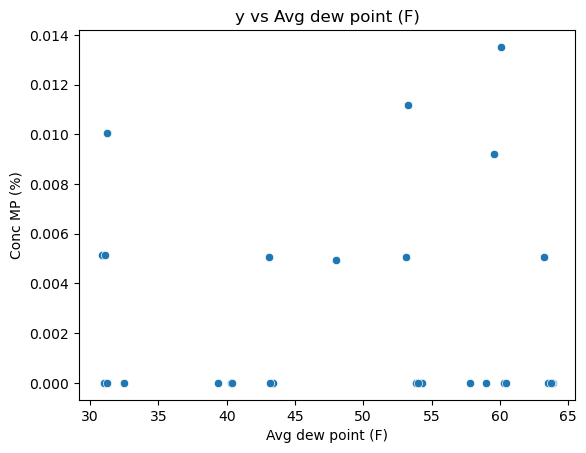

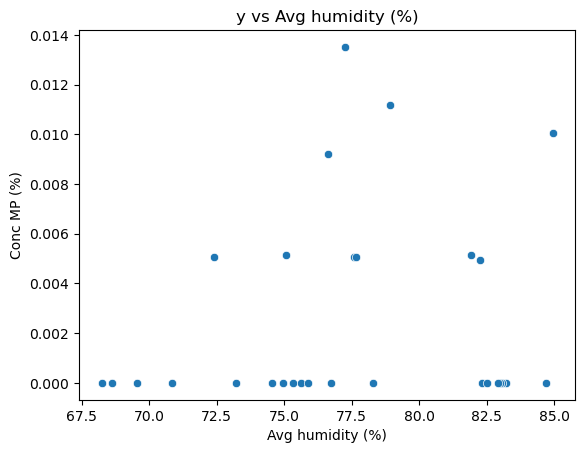

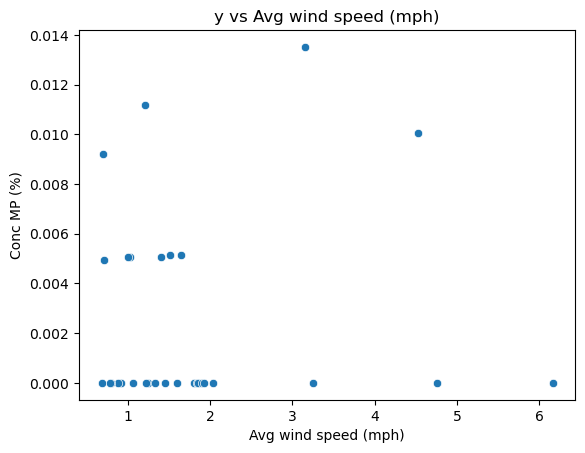

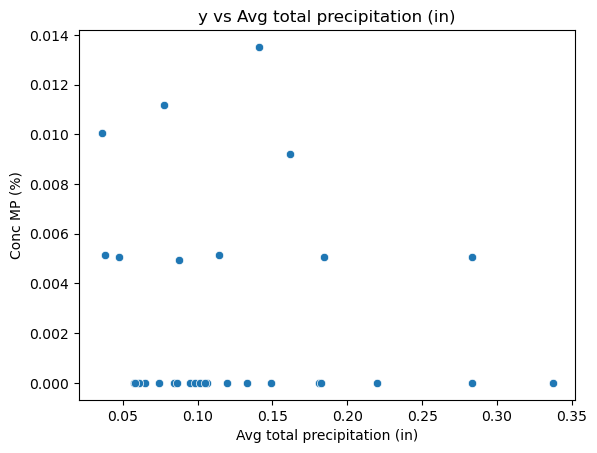

In [6]:
for col in num_vars:
    if col != 'Conc MP (%)':
        plt.figure()
        sns.scatterplot(x=passive_data[col], y=passive_data['Conc MP (%)'])
        plt.title(f"y vs {col}")
        plt.show()

In [7]:
passive_data.groupby('School').mean()['Conc MP (%)']

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_98121/2980377753.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  passive_data.groupby('School').mean()['Conc MP (%)']


School
DC     0.002435
FHS    0.002356
IAO    0.002640
Name: Conc MP (%), dtype: float64

In [8]:
passive_data.groupby('Month').mean()['Conc MP (%)']

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_98121/645331718.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  passive_data.groupby('Month').mean()['Conc MP (%)']


Month
Apr    0.000000
Aug    0.001642
Dec    0.005059
Jul    0.001684
Jun    0.007577
Mar    0.001709
May    0.001684
Nov    0.001692
Oct    0.003724
Sep    0.000000
Name: Conc MP (%), dtype: float64

In [9]:
np.corrcoef(np.array(X).T)

/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


array([[ 1.00000000e+00, -5.00000000e-01, -9.81307787e-18,
         2.61682076e-17, -9.81307787e-18, -9.81307787e-18,
         3.27102596e-18, -1.63551298e-17,  1.47196168e-17,
         3.27102596e-18, -3.27102596e-18,             nan,
        -9.65817400e-03,  4.66852443e-02,  1.72464634e-01,
         6.95980077e-01, -2.30167730e-01],
       [-5.00000000e-01,  1.00000000e+00, -3.27102596e-18,
         2.61682076e-17, -3.27102596e-18, -3.27102596e-18,
         1.63551298e-17, -9.81307787e-18,  1.47196168e-17,
         9.81307787e-18,  3.27102596e-18,             nan,
         1.76876103e-02,  3.70293567e-04, -3.50909746e-01,
        -2.44946600e-01,  1.16458665e-01],
       [-9.81307787e-18, -3.27102596e-18,  1.00000000e+00,
        -1.11111111e-01, -1.11111111e-01, -1.11111111e-01,
        -1.11111111e-01, -1.11111111e-01, -1.11111111e-01,
        -1.11111111e-01, -1.11111111e-01,             nan,
         3.52388291e-01,  2.56961712e-01,  2.39978021e-01,
        -1.72883443e-01,  1.4

<AxesSubplot: >

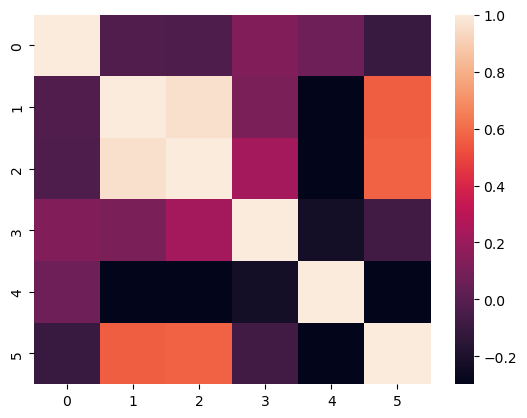

In [9]:
X = passive_data.loc[:, ['Conc MP (%)', 'Avg temperature (F)',
       'Avg dew point (F)', 'Avg humidity (%)', 'Avg wind speed (mph)',
       'Avg total precipitation (in)']]
sns.heatmap(np.corrcoef(np.array(X).T))

(array([20.,  0.,  0.,  6.,  0.,  0.,  1.,  1.,  1.,  1.]),
 array([ 0.       ,  1.3513514,  2.7027028,  4.0540542,  5.4054056,
         6.756757 ,  8.1081084,  9.4594598, 10.8108112, 12.1621626,
        13.513514 ]),
 <BarContainer object of 10 artists>)

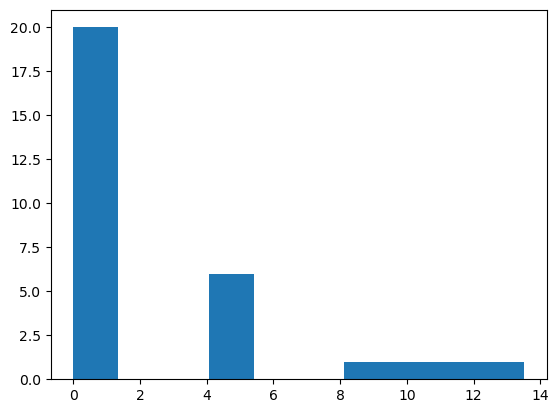

In [10]:
plt.hist(y)

In [11]:
f_test = model.f_test("School_FHS = 0, School_IAO = 0")
f_test

<class 'statsmodels.stats.contrast.ContrastResults'>
<F test: F=0.5101221846308928, p=0.6119564242189947, df_denom=13, df_num=2>

In [12]:
f_test = model.f_test('Month_Aug=0, Month_Dec=0, Month_Jul=0, Month_Jun=0, Month_Mar=0, Month_May=0, Month_Nov=0, Month_Oct=0, Month_Sep=0')
f_test

<class 'statsmodels.stats.contrast.ContrastResults'>
<F test: F=1.1124398774612758, p=0.4176418693675164, df_denom=13, df_num=9>

In [22]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            Conc MP (%)   R-squared:                       0.481
Model:                            OLS   Adj. R-squared:                 -0.157
Method:                 Least Squares   F-statistic:                    0.7536
Date:                Tue, 21 Apr 2026   Prob (F-statistic):              0.708
Time:                        21:11:47   Log-Likelihood:                -73.772
No. Observations:                  30   AIC:                             181.5
Df Residuals:                      13   BIC:                             205.4
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
School_FHS      

In [14]:
results = pd.DataFrame({
    "coef": model.params,
    "std_err": model.bse,
    "t_stat": model.tvalues,
    "p_value": model.pvalues
})

print(results)


                                   coef     std_err    t_stat   p_value
School_FHS                    -2.953932    4.093043 -0.721696  0.483261
School_IAO                     3.103151    4.130788  0.751225  0.465900
Month_Aug                     34.153937   61.564712  0.554765  0.588474
Month_Dec                    -29.785022   33.240087 -0.896057  0.386514
Month_Jul                     33.969007   60.222178  0.564061  0.582313
Month_Jun                     41.000846   51.107513  0.802247  0.436831
Month_Mar                    -20.759159   27.906510 -0.743882  0.470180
Month_May                     24.604292   36.363409  0.676622  0.510506
Month_Nov                      1.160141   10.857162  0.106855  0.916536
Month_Oct                     19.347098   36.660960  0.527730  0.606577
Month_Sep                     27.859686   51.923690  0.536551  0.600640
const                         37.866431  196.109482  0.193088  0.849874
Avg temperature (F)           -1.596296    2.728638 -0.585016  0

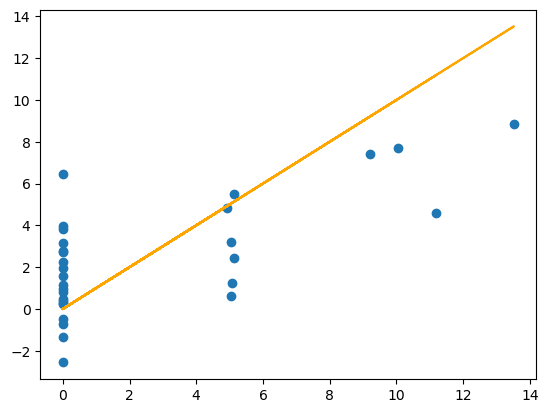

In [21]:
plt.scatter(
    y,    
    model.predict(X)
)
plt.plot(
    y,    
    y,
    c='orange'
)